# Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn import metrics
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

# Import Dataset

In [3]:
df = pd.read_csv('credit_card_default_clients.csv', header=1, index_col=0)

In [4]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
ID,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 1 to 30000
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   LIMIT_BAL                   30000 non-null  int64
 1   SEX                         30000 non-null  int64
 2   EDUCATION                   30000 non-null  int64
 3   MARRIAGE                    30000 non-null  int64
 4   AGE                         30000 non-null  int64
 5   PAY_0                       30000 non-null  int64
 6   PAY_2                       30000 non-null  int64
 7   PAY_3                       30000 non-null  int64
 8   PAY_4                       30000 non-null  int64
 9   PAY_5                       30000 non-null  int64
 10  PAY_6                       30000 non-null  int64
 11  BILL_AMT1                   30000 non-null  int64
 12  BILL_AMT2                   30000 non-null  int64
 13  BILL_AMT3                   30000 non-null  int64
 14  BILL_AMT4        

# Explore Dataset

1. SEX: Gender (1=male, 2=female)

2. EDUCATION: (1=graduate school, 2=university, 3=high school, 4=others, 5=unknown, 6=unknown)

3. MARRIAGE: Marital status (1=married, 2=single, 3=others)

4. LIMIT_BAL: Amount of given credit in NT dollars (includes individual and family/supplementary credit

5. PAY_0: Repayment status in September, 2005 (-1=pay duly, 1=payment delay for one month, 2=payment delay for two months,8=payment delay for eight months, 9=payment delay for nine months and above)
6. PAY_2 - PAY_6: August, July, June, May, April

7. BILL_AMT1: Amount of bill statement in September, 2005 (NT dollar)
8. BILL_AMT2 - BILL_AMT6: August, July, June, May, April

9. PAY_AMT1: Amount of previous payment in September, 2005 (NT dollar)
10. PAY_AMT2 - PAY_AMT6: August, July, June, May, April

11. default.payment.next.month: Default payment (1=yes, 0=no)

In [43]:
print("Percentage of default entries: ", df['default payment next month'].sum()/df['default payment next month'].count()*100,"%")

Percentage of default entries:  22.12 %


The feature with greatest positive correlation with default is  PAY_0
The feature with greatest negative correlation with default is  LIMIT_BAL


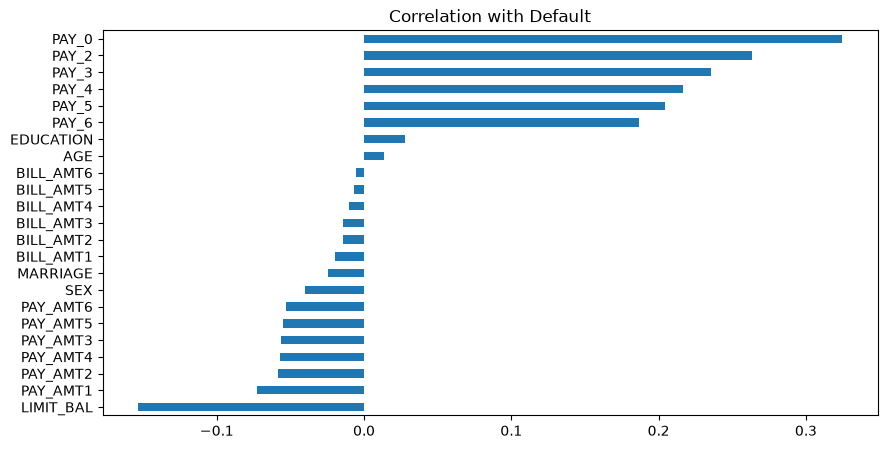

In [64]:
X = df.drop(['default payment next month'],axis=1)
X.corrwith(df['default payment next month']).sort_values().plot.barh(figsize = (10, 5), title = "Correlation with Default")
print("The feature with greatest positive correlation with default is ", df.columns[X.corrwith(df['default payment next month']).argmax()])
print("The feature with greatest negative correlation with default is ", df.columns[X.corrwith(df['default payment next month']).argmin()])

# Data Cleaning

In [67]:
df['EDUCATION'].value_counts()

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

As EDUCATION = 5 and EDUCATION = 6 represents "unknown", EDUCATION = 0 is undocumented, we can safely put them all into EDUCATION = 4 corresponding to "others"

In [69]:
df.loc[(df['EDUCATION'] == 5) | (df['EDUCATION'] == 6) | (df['EDUCATION'] == 0), 'EDUCATION'] = 4
df['EDUCATION'].value_counts()

EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64